# WP1: Sun-Earth and Sun-Mars Lagrange points

## Personal problem specification 

| Parameter | Value |
|-----------|-------|
| Sun/Earth Lagrange point | L2 |
| Sun/Mars Lagrange point | L2 |
| Shift in Lagrange points | 0.00100 |
| Radius Martian parking orbit | 244,444 km |
| Lightness number | 0.0300 |

## Constants and parameter values

In [1]:
AU = 149597870.7  # km
year_in_seconds = 365.256 * 24 * 3600  # s
mu_mars = 0.042828e6 # km^3 s^-2
mu_sun = 132712e6  # km^3 s^-2
mass_ratio_sun_earth = 3.0542e-6
mass_ratio_sun_mars = 3.227154996101724e-7
time_unit_sun_mars = 8253622 # s
length_unit_sun_mars = 208321282 # km

## Library imports

In [2]:
import numpy as np
import scipy 
import matplotlib.pyplot as plt

## Task 1.1a 
Compute the coordinates of the Sun-Earth and Sun-Mars colinear Lagrange points in your
personal problem specification using Newton’s method.

### Common to the both systems

Equation to be solved

In [3]:
def dUdx_colinear(x, mu):
    """
    Computes derivative of potential for collinear Lagrange points (y = z = 0):
    Accepts scalar x.
    """
    r1 = np.abs(x + mu)
    r2 = np.abs(x - 1 + mu)
    return x - (1.0 - mu) * (x + mu) / r1**3 - mu * (x - 1 + mu) / r2**3

Plotting of the points

In [4]:
def plot_colinear_points(lagrange_points, system_name, xlim=(-1.2, 1.2)):
    plt.figure(figsize=(12, 1.5))
    plt.axhline(0, color='gray', linewidth=1)
    lagrange_points = np.asarray(lagrange_points)
    plt.scatter(lagrange_points, np.zeros_like(lagrange_points), s=10, c='red', marker='x', zorder=4, label='Lagrange points')
    for i, x in enumerate(lagrange_points, start=1):
        plt.text(x, -0.08, f'L{i}', ha='center')

    plt.xlim(xlim)
    plt.ylim(-0.1, 0.1)
    plt.yticks([])
    plt.xlabel('x (normalized units)')
    plt.ylabel('dU/dx')
    plt.title(f'Collinear Lagrange Points - {system_name}')
    plt.grid()
    plt.legend()
    plt.show()

### Sun-Earth system

In [5]:
L1_earth = scipy.optimize.newton(dUdx_colinear, 0.5, args=(mass_ratio_sun_earth,))
L2_earth = scipy.optimize.newton(dUdx_colinear, 1.5, args=(mass_ratio_sun_earth,))
L3_earth = scipy.optimize.newton(dUdx_colinear, -0.5, args=(mass_ratio_sun_earth,))
lagrange_points_earth = [L1_earth, L2_earth, L3_earth]

In [6]:
print(f"For the personal problem specification --> L2 Sun-Earth: {L2_earth:.10f}")

For the personal problem specification --> L2 Sun-Earth: 1.0100904358


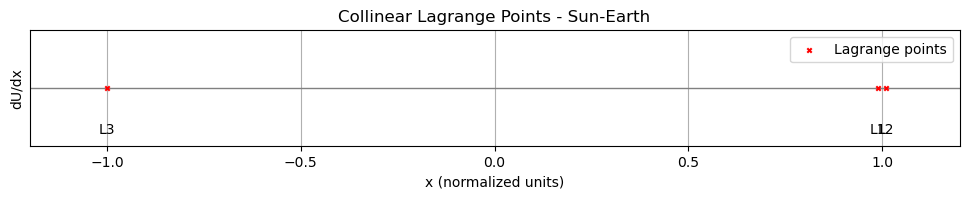

In [7]:
plot_colinear_points(lagrange_points_earth, "Sun-Earth")

### Sun-Mars system

In [8]:
L1_mars = scipy.optimize.newton(dUdx_colinear, 0.5, args=(mass_ratio_sun_mars,))
L2_mars = scipy.optimize.newton(dUdx_colinear, 1.5, args=(mass_ratio_sun_mars,))
L3_mars = scipy.optimize.newton(dUdx_colinear, -0.5, args=(mass_ratio_sun_mars,))
lagrange_points_mars = [L1_mars, L2_mars, L3_mars]

In [9]:
print(f"For the personal problem specification --> L2 Sun-Mars: {L2_mars:.10f}")

For the personal problem specification --> L2 Sun-Mars: 1.0047631067


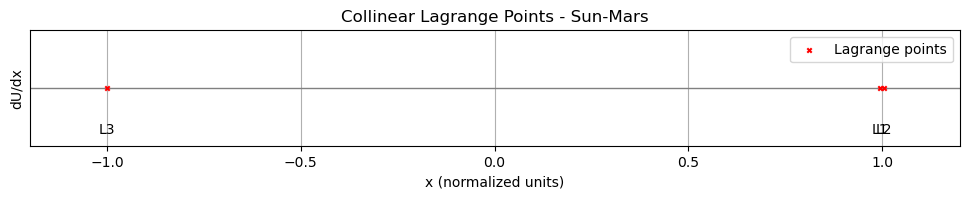

In [10]:
plot_colinear_points(lagrange_points_mars, "Sun-Mars")

## Verification of the results

### Residual check

For Earth-Sun system:

In [11]:
for i, L in enumerate(lagrange_points_earth):
    print(f"dU/dx at Earth-Sun Lagrange point {i+1}: {dUdx_colinear(L, mass_ratio_sun_earth):.2e}")

dU/dx at Earth-Sun Lagrange point 1: -8.64e-15
dU/dx at Earth-Sun Lagrange point 2: -3.82e-12
dU/dx at Earth-Sun Lagrange point 3: 7.97e-14


For Mars-Sun system:

In [12]:
for i, L in enumerate(lagrange_points_mars):
    print(f"dU/dx at Mars-Sun Lagrange point {i+1}: {dUdx_colinear(L, mass_ratio_sun_mars):.2e}")

dU/dx at Mars-Sun Lagrange point 1: 7.97e-12
dU/dx at Mars-Sun Lagrange point 2: 6.78e-14
dU/dx at Mars-Sun Lagrange point 3: 7.91e-14


### Check with published values

#### Comparison with [Koon, Lo, Marsden & Ross *Dynamical Systems, the Three-Body Problem and Space Mission Design*](https://www.cds.caltech.edu/~marsden/volume/missiondesign/KoLoMaRo_DMissionBook_2011-04-25.pdf#page=49.64)

In [13]:
mass_ratio_sun_jupiter = 9.537e-4 
L1_jupiter_paper = 0.9324
L1_jupiter = scipy.optimize.newton(dUdx_colinear, 0.5, args=(mass_ratio_sun_jupiter,))
print(f"Difference: {abs(L1_jupiter - L1_jupiter_paper):.2e}")

Difference: 3.02e-05


#### Comparison with [Wakker *Fundamentals of Astrodynamics*](https://www.researchgate.net/profile/Karel-Wakker/publication/272507882_Fundamentals_of_Astrodynamics/links/54e7ad0e0cf27a6de10ac2a8/Fundamentals-of-Astrodynamics.pdf)

$$\gamma_1 = (1-\mu) - x_{L_1}$$

$$\gamma_2 = x_{L_2} - (1-\mu)$$

$$\gamma_3 = -\mu - x_{L_3}$$

Mars-Sun comparison:

In [14]:
mass_ratio_sun_mars = 3.227e-7
L1_mars = scipy.optimize.newton(dUdx_colinear, 0.5, args=(mass_ratio_sun_mars,))
L2_mars = scipy.optimize.newton(dUdx_colinear, 1.5, args=(mass_ratio_sun_mars,))
L3_mars = scipy.optimize.newton(dUdx_colinear, -0.5, args=(mass_ratio_sun_mars,))
lagrange_points_mars = [L1_mars, L2_mars, L3_mars]

gammas_mars_wakker = [4.748e-3, 4.763e-3, 1.00000]
gammas_mars = [(1 - mass_ratio_sun_mars) - L1_mars, L2_mars - (1 - mass_ratio_sun_mars), -mass_ratio_sun_mars - L3_mars]

print("Gammas for Mars-Sun system:")
for i, (gamma_wakker, gamma_calc) in enumerate(zip(gammas_mars_wakker, gammas_mars), start=1):
    print(f"L{i}: Wakker's gamma = {gamma_wakker:.6e}, Calculated gamma = {gamma_calc:.6e}, Difference = {abs(gamma_wakker - gamma_calc):.2e}")

Gammas for Mars-Sun system:
L1: Wakker's gamma = 4.748000e-03, Calculated gamma = 4.748275e-03, Difference = 2.75e-07
L2: Wakker's gamma = 4.763000e-03, Calculated gamma = 4.763353e-03, Difference = 3.53e-07
L3: Wakker's gamma = 1.000000e+00, Calculated gamma = 9.999998e-01, Difference = 1.88e-07


Venus-Sun comparison:

In [15]:
mass_ratio_sun_venus = 2.448e-6
L1_venus = scipy.optimize.newton(dUdx_colinear, 0.5, args=(mass_ratio_sun_venus,))
L2_venus = scipy.optimize.newton(dUdx_colinear, 1.5, args=(mass_ratio_sun_venus,))
L3_venus = scipy.optimize.newton(dUdx_colinear, -0.5, args=(mass_ratio_sun_venus,))
lagrange_points_venus = [L1_venus, L2_venus, L3_venus]

gammas_venus_wakker = [9.315e-3, 9.373e-3, 1.0]
gammas_venus = [(1 - mass_ratio_sun_venus) - L1_venus, L2_venus - (1 - mass_ratio_sun_venus), -mass_ratio_sun_venus - L3_venus]

print("Gammas for Venus-Sun system:")
for i, (gamma_wakker, gamma_calc) in enumerate(zip(gammas_venus_wakker, gammas_venus), start=1):
    print(f"L{i}: Wakker's gamma = {gamma_wakker:.6e}, Calculated gamma = {gamma_calc:.6e}, Difference = {abs(gamma_wakker - gamma_calc):.2e}")

Gammas for Venus-Sun system:
L1: Wakker's gamma = 9.315000e-03, Calculated gamma = 9.315465e-03, Difference = 4.65e-07
L2: Wakker's gamma = 9.373000e-03, Calculated gamma = 9.373679e-03, Difference = 6.79e-07
L3: Wakker's gamma = 1.000000e+00, Calculated gamma = 9.999986e-01, Difference = 1.43e-06


Sun-Jupiter validation: 

In [16]:
mass_ratio_sun_jupiter = 9.537e-4
L1_jupiter = scipy.optimize.newton(dUdx_colinear, 0.5, args=(mass_ratio_sun_jupiter,))
L2_jupiter = scipy.optimize.newton(dUdx_colinear, 1.5, args=(mass_ratio_sun_jupiter,))
L3_jupiter = scipy.optimize.newton(dUdx_colinear, -0.5, args=(mass_ratio_sun_jupiter,))
lagrange_points_jupiter = [L1_jupiter, L2_jupiter, L3_jupiter]

gammas_jupiter_wakker = [6.668e-2, 6.978e-2, 0.99944]
gammas_jupiter = [(1 - mass_ratio_sun_jupiter) - L1_jupiter, L2_jupiter - (1 - mass_ratio_sun_jupiter), -mass_ratio_sun_jupiter - L3_jupiter]

print("Gammas for Jupiter-Sun system:")
for i, (gamma_wakker, gamma_calc) in enumerate(zip(gammas_jupiter_wakker, gammas_jupiter), start=1):
    print(f"L{i}: Wakker's gamma = {gamma_wakker:.6e}, Calculated gamma = {gamma_calc:.6e}, Difference = {abs(gamma_wakker - gamma_calc):.2e}")

Gammas for Jupiter-Sun system:
L1: Wakker's gamma = 6.668000e-02, Calculated gamma = 6.667655e-02, Difference = 3.45e-06
L2: Wakker's gamma = 6.978000e-02, Calculated gamma = 6.978003e-02, Difference = 2.66e-08
L3: Wakker's gamma = 9.994400e-01, Calculated gamma = 9.994437e-01, Difference = 3.67e-06
